In [22]:

# ============================================================
# AD CLICK PREDICTION - BUSINESS CASE STUDY
# PHASE 1: DATA LOADING AND EXPLORATORY DATA ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

warnings.filterwarnings('ignore')

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Load datasets
train = pd.read_csv('/content/Ad_click_prediction_train (1).csv')
test = pd.read_csv('/content/Ad_Click_prediciton_test.csv')

# Convert datetime
train['DateTime'] = pd.to_datetime(train['DateTime'])
test['DateTime'] = pd.to_datetime(test['DateTime'])

print("Training Shape:", train.shape)
print("Testing Shape:", test.shape)

print("\nTraining Dataset:")
display(train.head())

print("\nTesting Dataset:")
display(test.head())


Training Shape: (463291, 15)
Testing Shape: (128858, 14)

Training Dataset:


,session_id,DateTime,user_id,product,campaign_id,webpage_id,product_category_1,product_category_2,user_group_id,gender,age_level,user_depth,city_development_index,var_1,is_click
0,140690,2017-07-02 00:00:00,858557,C,359520,13787,4,NaN,10.0,Female,4.0,3.0,3.0,0,0
1,333291,2017-07-02 00:00:00,243253,C,105960,11085,5,NaN,8.0,Female,2.0,2.0,NaN,0,0
2,129781,2017-07-02 00:00:00,243253,C,359520,13787,4,NaN,8.0,Female,2.0,2.0,NaN,0,0
3,464848,2017-07-02 00:00:00,1097446,I,359520,13787,3,NaN,3.0,Male,3.0,3.0,2.0,1,0
4,90569,2017-07-02 00:01:00,663656,C,405490,60305,3,NaN,2.0,Male,2.0,3.0,2.0,1,0



Testing Dataset:


,session_id,DateTime,user_id,product,campaign_id,webpage_id,product_category_1,product_category_2,user_group_id,gender,age_level,user_depth,city_development_index,var_1
0,411705,2017-07-08,732573,J,404347,53587,1,NaN,5.0,Male,5.0,3.0,NaN,0
1,208263,2017-07-08,172910,I,118601,28529,3,82527.0,NaN,NaN,NaN,NaN,NaN,1
2,239450,2017-07-08,172910,I,118601,28529,4,82527.0,NaN,NaN,NaN,NaN,NaN,1
3,547761,2017-07-08,557318,G,118601,28529,5,82527.0,1.0,Male,1.0,3.0,1.0,0
4,574275,2017-07-08,923896,H,118601,28529,5,82527.0,9.0,Female,3.0,1.0,NaN,1


In [23]:

# Dataset information
print("TRAINING DATA INFORMATION")
train.info()

print("\nTEST DATA INFORMATION")
test.info()

# Statistical summary
print("\nNUMERICAL SUMMARY")
display(train.describe().T)

# Missing values
missing = pd.DataFrame({
    'Missing_Count': train.isnull().sum(),
    'Missing_Percentage': train.isnull().mean() * 100
})

missing = missing[missing['Missing_Count'] > 0]
missing = missing.sort_values(
    'Missing_Percentage', ascending=False
)

display(missing)

# Duplicate records
print("Duplicate rows:", train.duplicated().sum())

# Unique values
print("\nUNIQUE VALUES")
display(train.nunique().sort_values(ascending=False))


TRAINING DATA INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 463291 entries, 0 to 463290
Data columns (total 15 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   session_id              463291 non-null  int64         
 1   DateTime                463291 non-null  datetime64[ns]
 2   user_id                 463291 non-null  int64         
 3   product                 463291 non-null  object        
 4   campaign_id             463291 non-null  int64         
 5   webpage_id              463291 non-null  int64         
 6   product_category_1      463291 non-null  int64         
 7   product_category_2      97437 non-null   float64       
 8   user_group_id           445048 non-null  float64       
 9   gender                  445048 non-null  object        
 10  age_level               445048 non-null  float64       
 11  user_depth              445048 non-null  float64       
 12  city

,count,mean,min,25%,50%,75%,max,std
session_id,463291.0,285544.090725,2.0,137856.5,285429.0,435535.5,595812.0,168577.345887
DateTime,463291,2017-07-05 00:34:46.840020736,2017-07-02 00:00:00,2017-07-03 12:01:00,2017-07-04 22:01:00,2017-07-06 12:38:00,2017-07-07 23:59:00,NaN
user_id,463291.0,546049.654772,4.0,257855.0,531801.0,827849.0,1141729.0,329462.525854
campaign_id,463291.0,308474.540069,82320.0,118601.0,359520.0,405490.0,414149.0,126517.101294
webpage_id,463291.0,29685.878994,1734.0,13787.0,13787.0,53587.0,60305.0,21542.053106
product_category_1,463291.0,3.072427,1.0,2.0,3.0,4.0,5.0,1.304233
product_category_2,97437.0,162753.345105,18595.0,82527.0,146115.0,254132.0,450184.0,78743.74272
user_group_id,445048.0,3.477396,0.0,2.0,3.0,4.0,12.0,2.412889
age_level,445048.0,2.782266,0.0,2.0,3.0,3.0,6.0,1.069701
user_depth,445048.0,2.878415,1.0,3.0,3.0,3.0,3.0,0.40013


,Missing_Count,Missing_Percentage
product_category_2,365854,78.968510
city_development_index,125129,27.008727
user_group_id,18243,3.937698
gender,18243,3.937698
age_level,18243,3.937698
user_depth,18243,3.937698


Duplicate rows: 0

UNIQUE VALUES


,0
session_id,463291
user_id,150347
DateTime,8610
product_category_2,29
user_group_id,13
product,10
campaign_id,10
webpage_id,9
age_level,7
product_category_1,5


,Count,Percentage
is_click,,
0,431960,93.237296
1,31331,6.762704


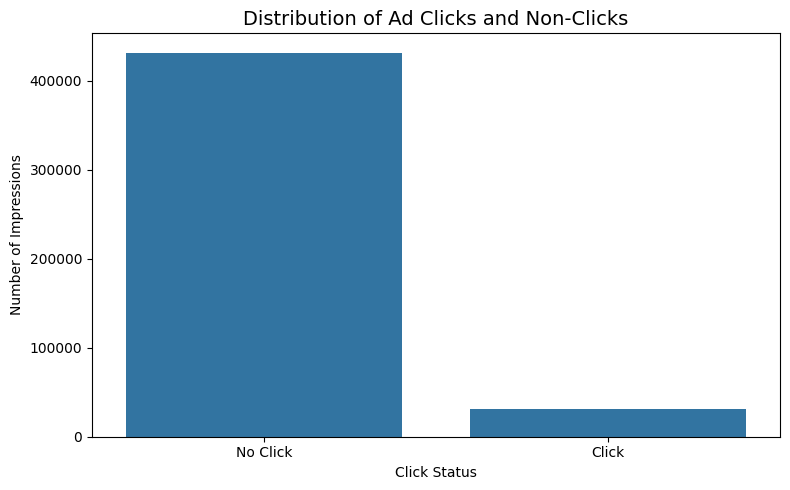

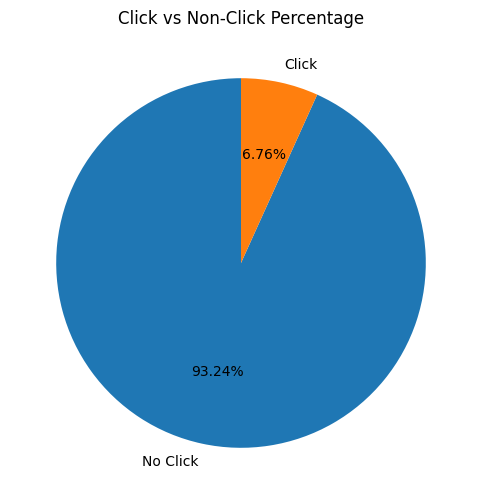

Overall CTR: 6.76 %


In [24]:

# Target distribution
target_counts = train['is_click'].value_counts().sort_index()
target_percentages = train['is_click'].value_counts(
    normalize=True
).sort_index() * 100

target_summary = pd.DataFrame({
    'Count': target_counts,
    'Percentage': target_percentages
})

display(target_summary)

# Visualization
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train,
    x='is_click'
)

plt.title('Distribution of Ad Clicks and Non-Clicks',
          fontsize=14)
plt.xlabel('Click Status')
plt.ylabel('Number of Impressions')
plt.xticks([0, 1], ['No Click', 'Click'])
plt.tight_layout()
plt.show()

# Pie chart
plt.figure(figsize=(6, 6))

plt.pie(
    target_counts,
    labels=['No Click', 'Click'],
    autopct='%1.2f%%',
    startangle=90
)

plt.title('Click vs Non-Click Percentage')
plt.show()

print("Overall CTR:", round(train['is_click'].mean()*100, 2), "%")


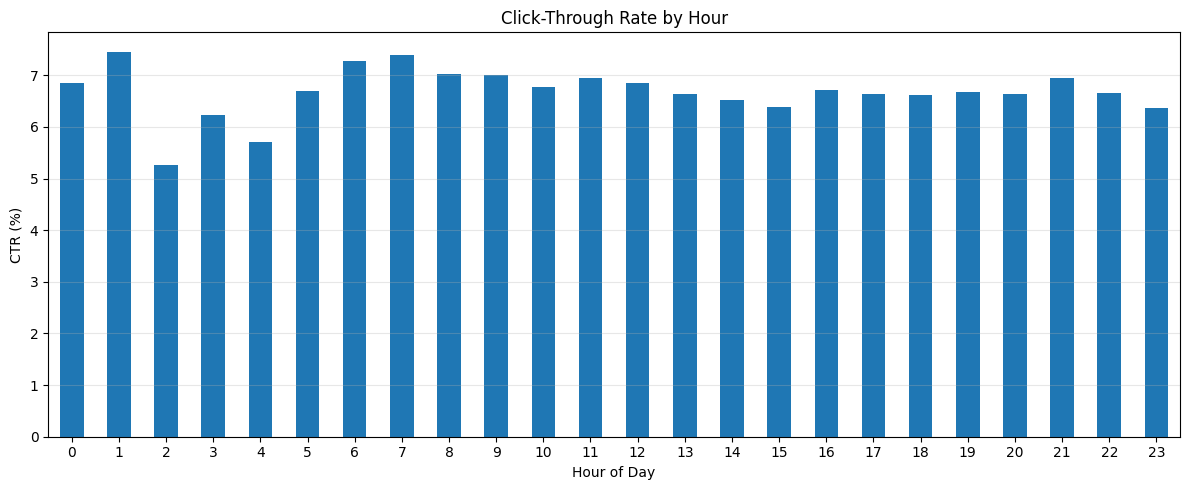

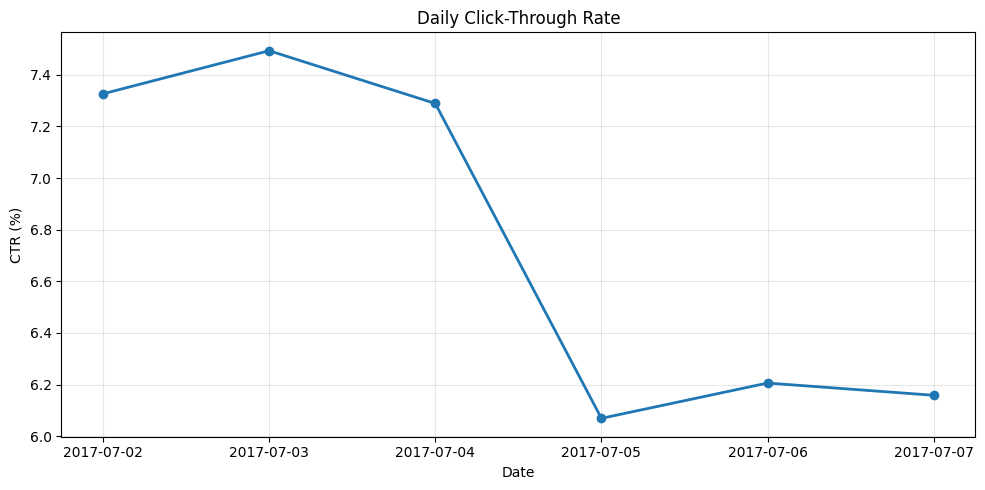

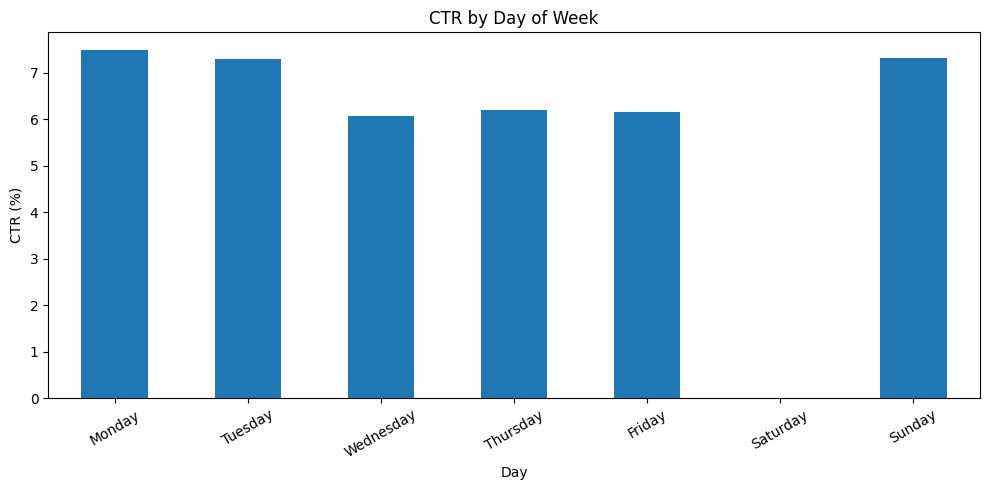

,is_click
day_of_week,
Monday,7.493242
Tuesday,7.288773
Wednesday,6.068896
Thursday,6.205660
Friday,6.158173
Saturday,NaN
Sunday,7.326207


In [25]:

# Extract temporal features for EDA
eda = train.copy()

eda['hour'] = eda['DateTime'].dt.hour
eda['day_of_week'] = eda['DateTime'].dt.day_name()
eda['day_of_month'] = eda['DateTime'].dt.day
eda['month'] = eda['DateTime'].dt.month

eda['is_weekend'] = (
    eda['DateTime'].dt.dayofweek >= 5
).astype(int)

# Hourly CTR
hourly_ctr = eda.groupby('hour')['is_click'].mean() * 100

plt.figure(figsize=(12, 5))
hourly_ctr.plot(kind='bar')

plt.title('Click-Through Rate by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('CTR (%)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Daily CTR
daily_ctr = eda.groupby(
    eda['DateTime'].dt.date
)['is_click'].mean() * 100

plt.figure(figsize=(10, 5))
daily_ctr.plot(marker='o', linewidth=2)

plt.title('Daily Click-Through Rate')
plt.xlabel('Date')
plt.ylabel('CTR (%)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Day of week
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

day_ctr = (
    eda.groupby('day_of_week')['is_click'].mean()
    .reindex(day_order) * 100
)

plt.figure(figsize=(10, 5))
day_ctr.plot(kind='bar')

plt.title('CTR by Day of Week')
plt.xlabel('Day')
plt.ylabel('CTR (%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(day_ctr)


PRODUCT PERFORMANCE


,product,impressions,clicks,ctr
9,J,9698,899,9.269953
3,D,41064,2949,7.181473
7,H,109574,7654,6.985234
2,C,163501,11306,6.914942
4,E,21452,1474,6.871154
8,I,63711,4079,6.402348
0,A,15391,953,6.191930
1,B,22479,1238,5.507362
5,F,7007,344,4.909376
6,G,9414,435,4.620778


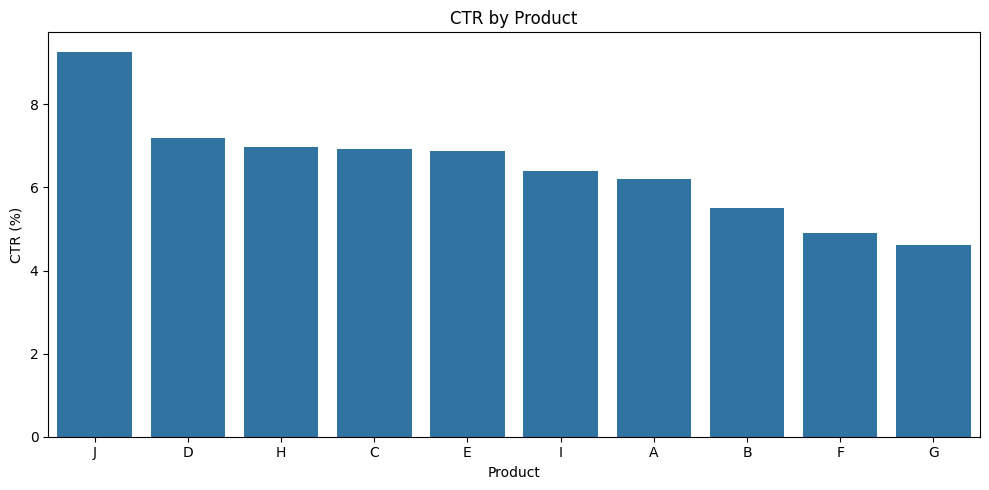

TOP 10 CAMPAIGNS


,campaign_id,impressions,clicks,ctr
8,405490,95973,8763,9.130693
7,404347,28826,2235,7.753417
1,98970,35065,2694,7.682875
6,396664,24909,1809,7.262435
2,105960,25781,1762,6.834491
0,82320,27849,1776,6.377249
4,359520,108155,6340,5.861957
9,414149,29314,1710,5.833390
3,118601,35531,1896,5.336185
5,360936,51888,2346,4.521277


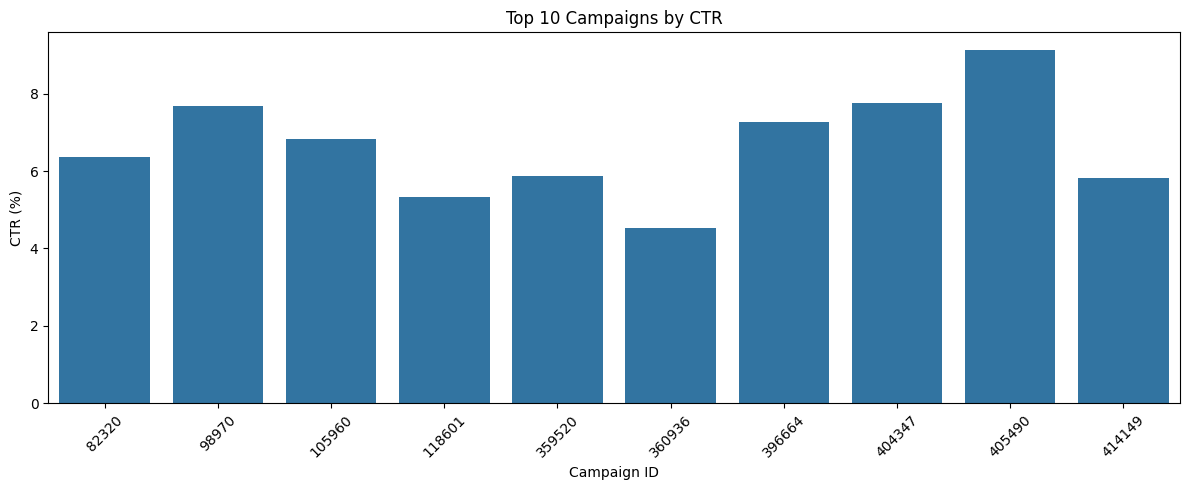

TOP 10 WEBPAGES


,webpage_id,impressions,clicks,ctr
8,60305,95973,8763,9.130693
7,53587,28826,2235,7.753417
1,6970,35065,2694,7.682875
6,51181,24909,1809,7.262435
2,11085,25781,1762,6.834491
0,1734,27849,1776,6.377249
5,45962,29314,1710,5.833390
3,13787,160043,8686,5.427291
4,28529,35531,1896,5.336185


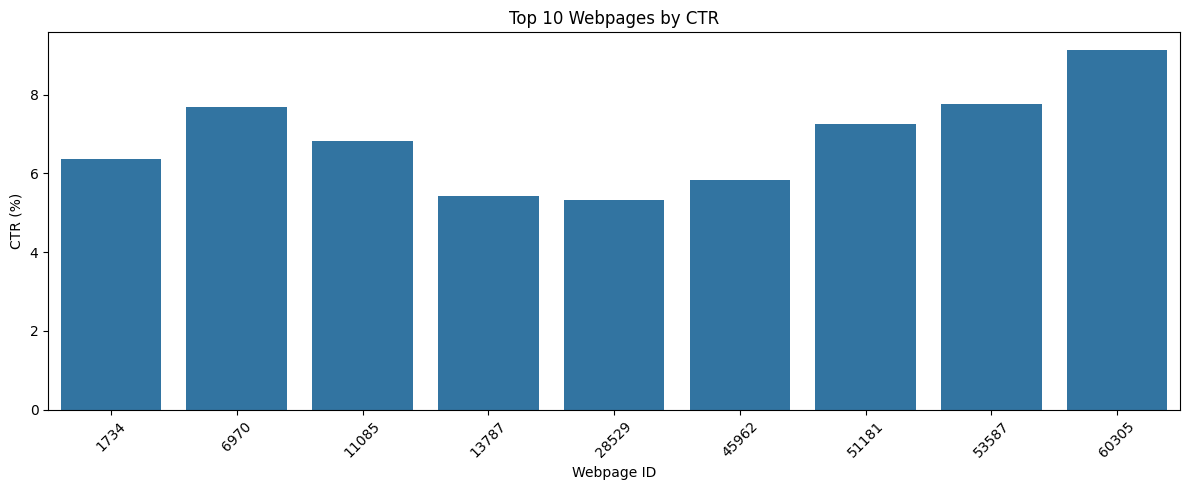

In [26]:

# Function to calculate CTR with impression counts
def calculate_ctr(data, column):
    result = data.groupby(column)['is_click'].agg(
        impressions='count',
        clicks='sum',
        ctr='mean'
    ).reset_index()

    result['ctr'] = result['ctr'] * 100

    return result.sort_values('ctr', ascending=False)


# Product performance
product_ctr = calculate_ctr(train, 'product')

print("PRODUCT PERFORMANCE")
display(product_ctr)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=product_ctr,
    x='product',
    y='ctr'
)

plt.title('CTR by Product')
plt.xlabel('Product')
plt.ylabel('CTR (%)')
plt.tight_layout()
plt.show()


# Campaign performance
campaign_ctr = calculate_ctr(train, 'campaign_id')

print("TOP 10 CAMPAIGNS")
display(campaign_ctr.head(10))

plt.figure(figsize=(12, 5))
sns.barplot(
    data=campaign_ctr.head(10),
    x='campaign_id',
    y='ctr'
)

plt.title('Top 10 Campaigns by CTR')
plt.xlabel('Campaign ID')
plt.ylabel('CTR (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Webpage performance
webpage_ctr = calculate_ctr(train, 'webpage_id')

print("TOP 10 WEBPAGES")
display(webpage_ctr.head(10))

plt.figure(figsize=(12, 5))
sns.barplot(
    data=webpage_ctr.head(10),
    x='webpage_id',
    y='ctr'
)

plt.title('Top 10 Webpages by CTR')
plt.xlabel('Webpage ID')
plt.ylabel('CTR (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



CTR ANALYSIS: gender


,gender,count,sum,mean,CTR (%)
2,NaN,18243,1274,0.069835,6.983501
1,Male,393454,26732,0.067942,6.794187
0,Female,51594,3325,0.064445,6.444548


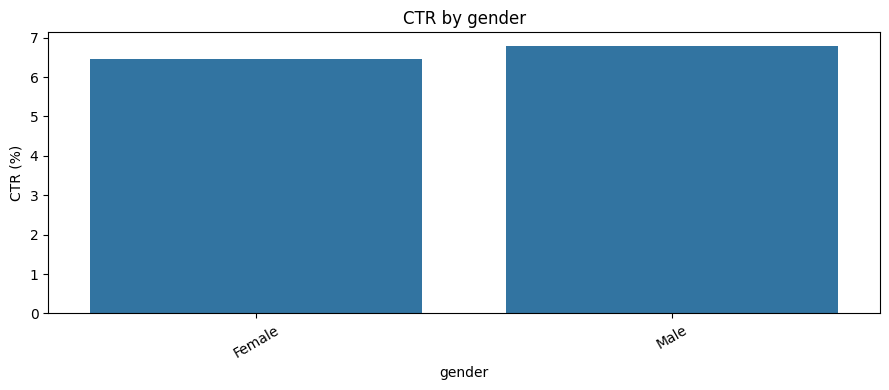


CTR ANALYSIS: age_level


,age_level,count,sum,mean,CTR (%)
0,0.0,153,13,0.084967,8.496732
6,6.0,2759,227,0.082276,8.227619
1,1.0,43367,3244,0.074803,7.480342
5,5.0,30828,2286,0.074153,7.415337
2,2.0,143501,10177,0.070919,7.091937
7,NaN,18243,1274,0.069835,6.983501
3,3.0,160581,10360,0.064516,6.451573
4,4.0,63859,3750,0.058723,5.872312


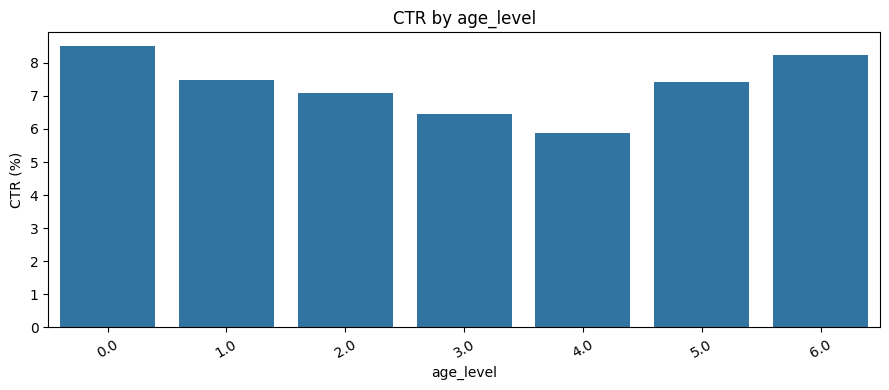


CTR ANALYSIS: user_group_id


,user_group_id,count,sum,mean,CTR (%)
12,12.0,1035,92,0.088889,8.888889
0,0.0,153,13,0.084967,8.496732
6,6.0,1724,135,0.078306,7.830626
11,11.0,8839,678,0.076706,7.670551
1,1.0,41946,3152,0.075144,7.514423
5,5.0,21989,1608,0.073127,7.312747
2,2.0,137278,9780,0.071242,7.124230
13,NaN,18243,1274,0.069835,6.983501
7,7.0,1421,92,0.064743,6.474314
3,3.0,140317,9074,0.064668,6.466786


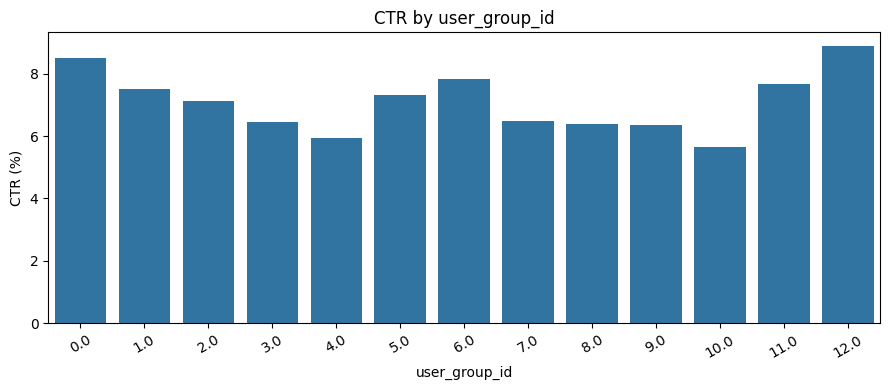


CTR ANALYSIS: user_depth


,user_depth,count,sum,mean,CTR (%)
0,1.0,11861,853,0.071916,7.191636
3,NaN,18243,1274,0.069835,6.983501
2,3.0,402798,27213,0.067560,6.755992
1,2.0,30389,1991,0.065517,6.551713


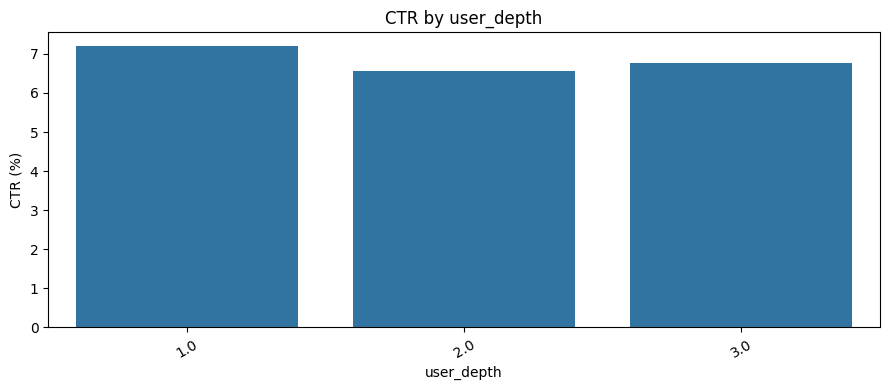


CTR ANALYSIS: city_development_index


,city_development_index,count,sum,mean,CTR (%)
1,2.0,147643,10311,0.069837,6.983738
4,NaN,125129,8482,0.067786,6.778604
0,1.0,34644,2321,0.066996,6.699573
2,3.0,88709,5828,0.065698,6.569796
3,4.0,67166,4389,0.065346,6.534556


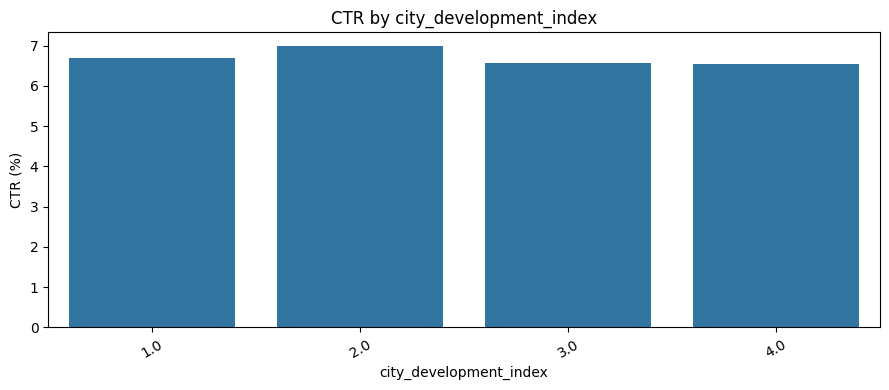


CTR ANALYSIS: product_category_1


,product_category_1,count,sum,mean,CTR (%)
2,3,113812,9506,0.083524,8.352371
0,1,81141,5806,0.071554,7.155445
1,2,69183,4270,0.061720,6.172036
4,5,65865,3894,0.059121,5.912093
3,4,133290,7855,0.058932,5.893165


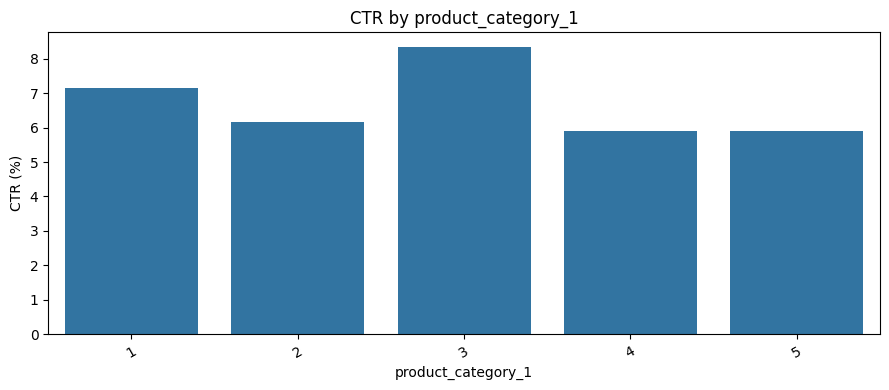


CTR ANALYSIS: var_1


,var_1,count,sum,mean,CTR (%)
1,1,195587,13876,0.070945,7.094541
0,0,267704,17455,0.065203,6.520261


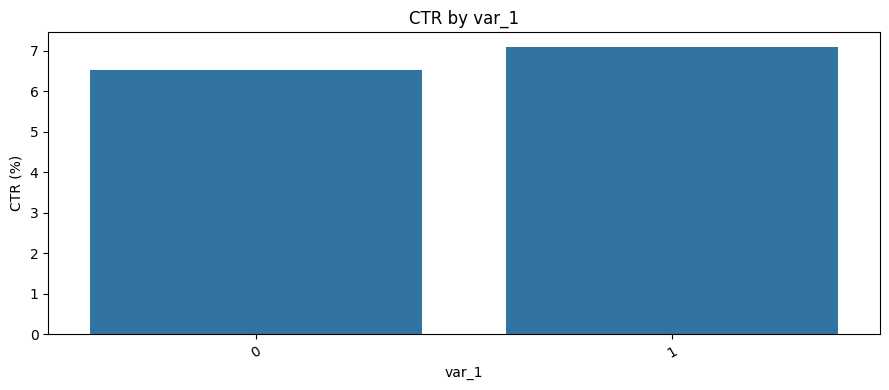

In [27]:

# Demographic and behavioral features
columns = [
    'gender',
    'age_level',
    'user_group_id',
    'user_depth',
    'city_development_index',
    'product_category_1',
    'var_1'
]

for col in columns:

    summary = (
        train.groupby(col, dropna=False)['is_click']
        .agg(['count', 'sum', 'mean'])
        .reset_index()
    )

    summary['CTR (%)'] = summary['mean'] * 100

    print(f"\nCTR ANALYSIS: {col}")
    display(summary.sort_values('CTR (%)', ascending=False))

    # Visualization
    plt.figure(figsize=(9, 4))

    sns.barplot(
        data=summary,
        x=col,
        y='CTR (%)'
    )

    plt.title(f'CTR by {col}')
    plt.xlabel(col)
    plt.ylabel('CTR (%)')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


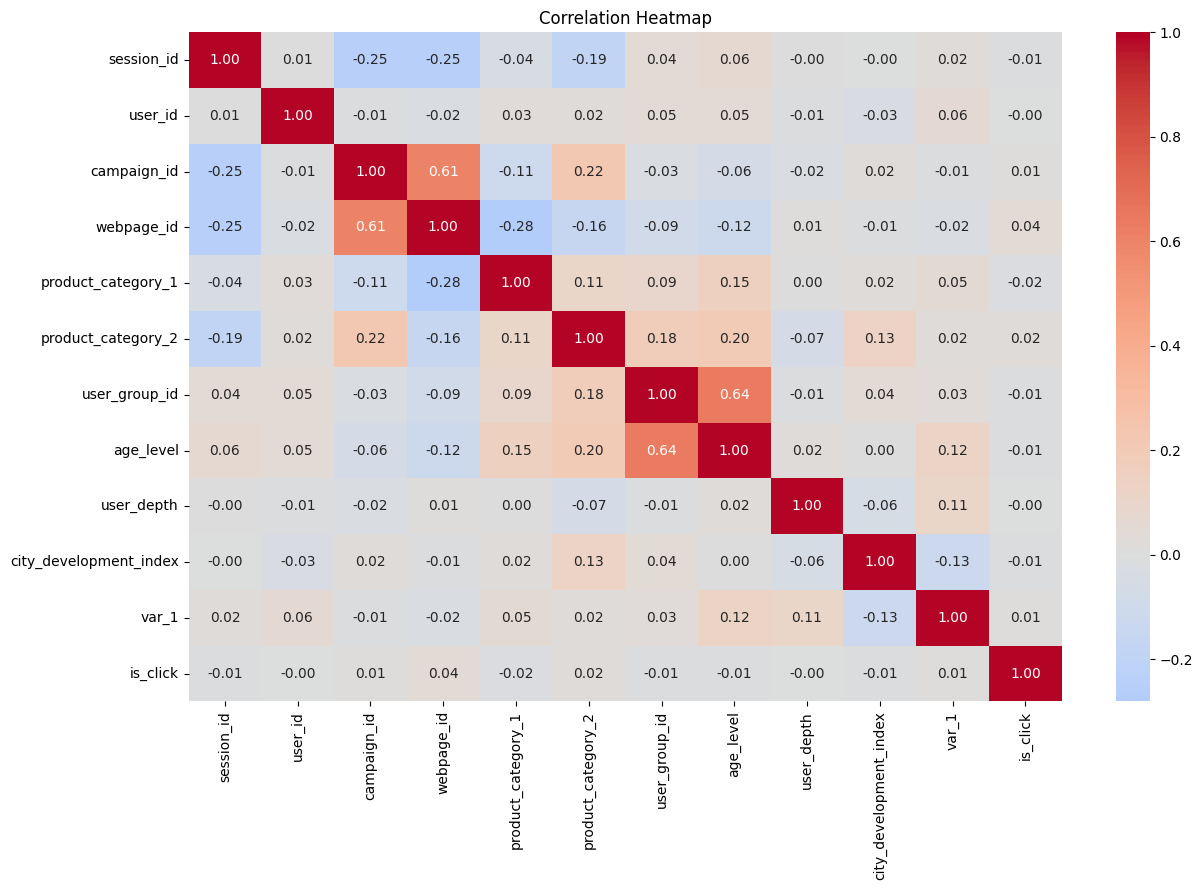

In [28]:

# Numerical correlation
numeric_data = train.select_dtypes(include=np.number)

correlation = numeric_data.corr()

plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()



## Phase 1: Exploratory Data Analysis - Key Findings

1. The training dataset contains 463,291 advertisement impressions and 15 columns.
2. The testing dataset contains 128,858 impressions and 14 columns.
3. The observed click-through rate is approximately 6.76%.
4. The target variable is imbalanced, with non-click impressions representing approximately 93.24% of observations.
5. Product J has the highest observed product CTR at approximately 9.27%, while Product G has the lowest at approximately 4.62%.
6. Campaign and webpage performance varies considerably.
7. Missing values are concentrated in product_category_2 and city_development_index.
8. Temporal patterns indicate differences in CTR across the observed dates and hours.
9. Demographic and behavioral characteristics provide potential segmentation opportunities.
10. The training period covers July 2-7, 2017, while the test period covers July 8-9, 2017.

### Business Implications

The exploratory findings indicate that advertising performance is not uniform across products, campaigns, webpages and user segments.

A predictive model could help advertisers prioritize impressions with higher click propensity, allocate campaign budgets more intelligently and improve advertising relevance.

These findings are descriptive and will be validated through leakage-free predictive modeling.


In [29]:

# Create engineered copies
train_fe = train.copy()
test_fe = test.copy()

def add_time_features(df):

    df = df.copy()

    df['hour'] = df['DateTime'].dt.hour
    df['day_of_week'] = df['DateTime'].dt.dayofweek
    df['day_of_month'] = df['DateTime'].dt.day
    df['month'] = df['DateTime'].dt.month

    df['is_weekend'] = (
        df['day_of_week'] >= 5
    ).astype(int)

    df['time_of_day'] = pd.cut(
        df['hour'],
        bins=[-1, 5, 11, 17, 23],
        labels=['Night', 'Morning', 'Afternoon', 'Evening']
    ).astype(str)

    return df

train_fe = add_time_features(train_fe)
test_fe = add_time_features(test_fe)

print("Temporal features created successfully.")

display(
    train_fe[
        ['DateTime', 'hour', 'day_of_week',
         'is_weekend', 'time_of_day']
    ].head()
)


Temporal features created successfully.


,DateTime,hour,day_of_week,is_weekend,time_of_day
0,2017-07-02 00:00:00,0,6,1,Night
1,2017-07-02 00:00:00,0,6,1,Night
2,2017-07-02 00:00:00,0,6,1,Night
3,2017-07-02 00:00:00,0,6,1,Night
4,2017-07-02 00:01:00,0,6,1,Night


In [30]:

# User-product interaction
for df in [train_fe, test_fe]:

    df['user_product_interaction'] = (
        df['user_id'].astype(str) + '_' +
        df['product'].astype(str)
    )

    # Campaign-webpage interaction
    df['campaign_webpage'] = (
        df['campaign_id'].astype(str) + '_' +
        df['webpage_id'].astype(str)
    )

    # Gender-age interaction
    df['gender_age'] = (
        df['gender'].fillna('Unknown').astype(str) + '_' +
        df['age_level'].fillna(-1).astype(str)
    )

print("Interaction features created.")

display(
    train_fe[
        ['user_product_interaction',
         'campaign_webpage',
         'gender_age']
    ].head()
)


Interaction features created.


,user_product_interaction,campaign_webpage,gender_age
0,858557_C,359520_13787,Female_4.0
1,243253_C,105960_11085,Female_2.0
2,243253_C,359520_13787,Female_2.0
3,1097446_I,359520_13787,Male_3.0
4,663656_C,405490_60305,Male_2.0


In [31]:

# Historical features using past observations only

def add_past_history_features(df):

    df = df.sort_values(
        ['DateTime', 'session_id']
    ).copy()

    groups = {
        'user_id': 'user',
        'product': 'product',
        'campaign_id': 'campaign',
        'webpage_id': 'webpage'
    }

    for column, prefix in groups.items():

        grouped = df.groupby(
            column,
            sort=False,
            dropna=False
        )['is_click']

        # Number of previous impressions
        df[f'{prefix}_historical_views'] = (
            grouped.cumcount()
        )

        # Number of previous clicks
        previous_clicks = (
            grouped.cumsum() - df['is_click']
        )

        df[f'{prefix}_historical_clicks'] = (
            previous_clicks
        )

        # Historical CTR
        df[f'{prefix}_historical_ctr'] = (
            previous_clicks /
            df[f'{prefix}_historical_views'].replace(0, np.nan)
        )

    # Replace undefined historical CTR for first observations
    df = df.fillna({
        'user_historical_ctr': 0,
        'product_historical_ctr': 0,
        'campaign_historical_ctr': 0,
        'webpage_historical_ctr': 0
    })

    return df


train_fe = add_past_history_features(train_fe)

print("Historical features generated.")
display(train_fe.head())


Historical features generated.


,session_id,DateTime,user_id,product,campaign_id,webpage_id,product_category_1,product_category_2,user_group_id,gender,...,user_historical_ctr,product_historical_views,product_historical_clicks,product_historical_ctr,campaign_historical_views,campaign_historical_clicks,campaign_historical_ctr,webpage_historical_views,webpage_historical_clicks,webpage_historical_ctr
2,129781,2017-07-02 00:00:00,243253,C,359520,13787,4,NaN,8.0,Female,...,0.0,0,0,0.0,0,0,0.0,0,0,0.0
0,140690,2017-07-02 00:00:00,858557,C,359520,13787,4,NaN,10.0,Female,...,0.0,1,0,0.0,1,0,0.0,1,0,0.0
1,333291,2017-07-02 00:00:00,243253,C,105960,11085,5,NaN,8.0,Female,...,0.0,2,0,0.0,0,0,0.0,0,0,0.0
3,464848,2017-07-02 00:00:00,1097446,I,359520,13787,3,NaN,3.0,Male,...,0.0,0,0,0.0,2,0,0.0,2,0,0.0
6,17583,2017-07-02 00:01:00,1091463,F,405490,60305,3,NaN,9.0,Female,...,0.0,0,0,0.0,0,0,0.0,0,0,0.0


In [32]:

# Display engineered features
print("Original training features:", train.shape[1])
print("Engineered training features:", train_fe.shape[1])

new_features = [
    col for col in train_fe.columns
    if col not in train.columns
]

print("\nNewly Created Features:")
for feature in new_features:
    print("-", feature)

print("\nEngineered Dataset Shape:", train_fe.shape)


Original training features: 15
Engineered training features: 36

Newly Created Features:
- hour
- day_of_week
- day_of_month
- month
- is_weekend
- time_of_day
- user_product_interaction
- campaign_webpage
- gender_age
- user_historical_views
- user_historical_clicks
- user_historical_ctr
- product_historical_views
- product_historical_clicks
- product_historical_ctr
- campaign_historical_views
- campaign_historical_clicks
- campaign_historical_ctr
- webpage_historical_views
- webpage_historical_clicks
- webpage_historical_ctr

Engineered Dataset Shape: (463291, 36)


In [33]:

# ============================================================
# PHASE 3: CHRONOLOGICAL DATA SPLITTING
# ============================================================

# Start with the original datasets
train = train.copy()
test = test.copy()

train['DateTime'] = pd.to_datetime(train['DateTime'])
test['DateTime'] = pd.to_datetime(test['DateTime'])

# Chronological split
model_train = train[
    train['DateTime'].dt.day <= 6
].copy()

validation = train[
    train['DateTime'].dt.day == 7
].copy()

final_test = test.copy()

print("Model training:", model_train.shape)
print("Validation:", validation.shape)
print("Final test:", final_test.shape)

print("\nTraining dates:")
print(model_train['DateTime'].min(),
      "to", model_train['DateTime'].max())

print("\nValidation dates:")
print(validation['DateTime'].min(),
      "to", validation['DateTime'].max())

print("\nTest dates:")
print(final_test['DateTime'].min(),
      "to", final_test['DateTime'].max())

print("\nTraining CTR:",
      round(model_train['is_click'].mean()*100, 2), "%")

print("Validation CTR:",
      round(validation['is_click'].mean()*100, 2), "%")


Model training: (391825, 15)
Validation: (71466, 15)
Final test: (128858, 14)

Training dates:
2017-07-02 00:00:00 to 2017-07-06 23:59:00

Validation dates:
2017-07-07 00:00:00 to 2017-07-07 23:59:00

Test dates:
2017-07-08 00:00:00 to 2017-07-09 21:29:00

Training CTR: 6.87 %
Validation CTR: 6.16 %


In [34]:

# ============================================================
# HISTORICAL FEATURE ENGINEERING
# Previous-day information only
# ============================================================

def build_historical_features(reference_data, target_data):

    reference = reference_data.copy()
    target = target_data.copy()

    reference['DateTime'] = pd.to_datetime(
        reference['DateTime']
    )
    target['DateTime'] = pd.to_datetime(
        target['DateTime']
    )

    reference['event_date'] = (
        reference['DateTime'].dt.normalize()
    )

    target['event_date'] = (
        target['DateTime'].dt.normalize()
    )

    entity_columns = [
        'user_id',
        'product',
        'campaign_id',
        'webpage_id'
    ]

    for entity in entity_columns:

        prefix = entity.replace('_id', '')

        # Daily historical statistics
        daily = (
            reference.groupby(
                [entity, 'event_date'],
                dropna=False
            )['is_click']
            .agg(['count', 'sum'])
            .reset_index()
            .sort_values([entity, 'event_date'])
        )

        # Previous days only
        grouped = daily.groupby(
            entity,
            dropna=False
        )

        daily[f'{prefix}_historical_views'] = (
            grouped['count'].cumsum() - daily['count']
        )

        daily[f'{prefix}_historical_clicks'] = (
            grouped['sum'].cumsum() - daily['sum']
        )

        daily[f'{prefix}_historical_ctr'] = (
            daily[f'{prefix}_historical_clicks'] /
            daily[f'{prefix}_historical_views'].replace(0, np.nan)
        )

        # Keep only required columns
        history = daily[
            [
                entity,
                'event_date',
                f'{prefix}_historical_views',
                f'{prefix}_historical_clicks',
                f'{prefix}_historical_ctr'
            ]
        ]

        # Merge into target dataset
        target = target.merge(
            history,
            on=[entity, 'event_date'],
            how='left',
            validate='many_to_one'
        )

        target[
            [
                f'{prefix}_historical_views',
                f'{prefix}_historical_clicks',
                f'{prefix}_historical_ctr'
            ]
        ] = target[
            [
                f'{prefix}_historical_views',
                f'{prefix}_historical_clicks',
                f'{prefix}_historical_ctr'
            ]
        ].fillna(0)

    return target.drop(columns=['event_date'])


# Training rows: expanding historical features
model_train_fe = build_historical_features(
    model_train,
    model_train
)

# Validation: history from the training period only
validation_fe = build_historical_features(
    model_train,
    validation
)

# Test: history from all labelled training data
final_test_fe = build_historical_features(
    train,
    final_test
)

print("Historical features successfully generated.")

display(model_train_fe.head())


Historical features successfully generated.


,session_id,DateTime,user_id,product,campaign_id,webpage_id,product_category_1,product_category_2,user_group_id,gender,...,user_historical_ctr,product_historical_views,product_historical_clicks,product_historical_ctr,campaign_historical_views,campaign_historical_clicks,campaign_historical_ctr,webpage_historical_views,webpage_historical_clicks,webpage_historical_ctr
0,140690,2017-07-02 00:00:00,858557,C,359520,13787,4,NaN,10.0,Female,...,0.0,0,0,0.0,0,0,0.0,0,0,0.0
1,333291,2017-07-02 00:00:00,243253,C,105960,11085,5,NaN,8.0,Female,...,0.0,0,0,0.0,0,0,0.0,0,0,0.0
2,129781,2017-07-02 00:00:00,243253,C,359520,13787,4,NaN,8.0,Female,...,0.0,0,0,0.0,0,0,0.0,0,0,0.0
3,464848,2017-07-02 00:00:00,1097446,I,359520,13787,3,NaN,3.0,Male,...,0.0,0,0,0.0,0,0,0.0,0,0,0.0
4,90569,2017-07-02 00:01:00,663656,C,405490,60305,3,NaN,2.0,Male,...,0.0,0,0,0.0,0,0,0.0,0,0,0.0


In [35]:

def add_model_features(df):

    df = df.copy()

    dt = pd.to_datetime(df['DateTime'])

    df['hour'] = dt.dt.hour
    df['day_of_week'] = dt.dt.dayofweek
    df['day_of_month'] = dt.dt.day
    df['month'] = dt.dt.month

    df['is_weekend'] = (
        dt.dt.dayofweek >= 5
    ).astype(int)

    df['time_of_day'] = pd.cut(
        df['hour'],
        bins=[-1, 5, 11, 17, 23],
        labels=['Night', 'Morning', 'Afternoon', 'Evening']
    ).astype(str)

    df['gender_age'] = (
        df['gender'].fillna('Unknown').astype(str)
        + '_'
        + df['age_level'].fillna(-1).astype(str)
    )

    df['campaign_webpage'] = (
        df['campaign_id'].astype(str)
        + '_'
        + df['webpage_id'].astype(str)
    )

    return df


model_train_fe = add_model_features(model_train_fe)
validation_fe = add_model_features(validation_fe)
final_test_fe = add_model_features(final_test_fe)

print("Feature engineering completed.")

print("Training:", model_train_fe.shape)
print("Validation:", validation_fe.shape)
print("Testing:", final_test_fe.shape)


Feature engineering completed.
Training: (391825, 35)
Validation: (71466, 35)
Testing: (128858, 34)


In [36]:

# Feature selection
target_column = 'is_click'

drop_columns = [
    'session_id',
    'DateTime',
    'user_id',
    'is_click'
]

X_train = model_train_fe.drop(
    columns=drop_columns
)

y_train = model_train_fe[target_column]

X_val = validation_fe.drop(
    columns=drop_columns
)

y_val = validation_fe[target_column]

X_test = final_test_fe.drop(
    columns=['session_id', 'DateTime', 'user_id'],
    errors='ignore'
)

# Ensure identical feature columns
X_test = X_test.reindex(
    columns=X_train.columns
)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Testing features:", X_test.shape)

assert list(X_train.columns) == list(X_val.columns)
assert list(X_train.columns) == list(X_test.columns)


Training features: (391825, 31)
Validation features: (71466, 31)
Testing features: (128858, 31)


In [37]:

# Treat identifier-like columns as categorical
categorical_columns = [
    'product',
    'campaign_id',
    'webpage_id',
    'product_category_1',
    'product_category_2',
    'user_group_id',
    'gender',
    'age_level',
    'user_depth',
    'city_development_index',
    'var_1',
    'time_of_day',
    'gender_age',
    'campaign_webpage'
]

categorical_columns = [
    col for col in categorical_columns
    if col in X_train.columns
]

numerical_columns = [
    col for col in X_train.columns
    if col not in categorical_columns
]

print("Numerical features:")
print(numerical_columns)

print("\nCategorical features:")
print(categorical_columns)

print("\nNumber of numerical features:",
      len(numerical_columns))

print("Number of categorical features:",
      len(categorical_columns))


Numerical features:
['user_historical_views', 'user_historical_clicks', 'user_historical_ctr', 'product_historical_views', 'product_historical_clicks', 'product_historical_ctr', 'campaign_historical_views', 'campaign_historical_clicks', 'campaign_historical_ctr', 'webpage_historical_views', 'webpage_historical_clicks', 'webpage_historical_ctr', 'hour', 'day_of_week', 'day_of_month', 'month', 'is_weekend']

Categorical features:
['product', 'campaign_id', 'webpage_id', 'product_category_1', 'product_category_2', 'user_group_id', 'gender', 'age_level', 'user_depth', 'city_development_index', 'var_1', 'time_of_day', 'gender_age', 'campaign_webpage']

Number of numerical features: 17
Number of categorical features: 14


In [38]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        min_frequency=20
    ))
])

# Combined preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_columns),
        ('cat', categorical_transformer, categorical_columns)
    ],
    remainder='drop'
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

print("Training processed shape:",
      X_train_processed.shape)

print("Validation processed shape:",
      X_val_processed.shape)

print("Missing values handled and encoding completed.")


Training processed shape: (391825, 126)
Validation processed shape: (71466, 126)
Missing values handled and encoding completed.


In [39]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Baseline Logistic Regression
logistic_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42,
    solver='lbfgs'
)

logistic_model.fit(
    X_train_processed,
    y_train
)

# Validation probabilities
logistic_prob = logistic_model.predict_proba(
    X_val_processed
)[:, 1]

# Default threshold
logistic_pred = (
    logistic_prob >= 0.5
).astype(int)

print("LOGISTIC REGRESSION RESULTS")

print("Accuracy:",
      accuracy_score(y_val, logistic_pred))

print("Precision:",
      precision_score(y_val, logistic_pred,
                      zero_division=0))

print("Recall:",
      recall_score(y_val, logistic_pred,
                   zero_division=0))

print("F1 Score:",
      f1_score(y_val, logistic_pred,
               zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_val, logistic_prob))

print("PR-AUC:",
      average_precision_score(y_val, logistic_prob))

print("\nClassification Report:")
print(classification_report(
    y_val,
    logistic_pred,
    zero_division=0
))


LOGISTIC REGRESSION RESULTS
Accuracy: 0.1425572999748132
Precision: 0.06324389906777449
Recall: 0.935696432628948
F1 Score: 0.11847973070172915
ROC-AUC: 0.5386951428066654
PR-AUC: 0.06962132578806382

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.09      0.17     67065
           1       0.06      0.94      0.12      4401

    accuracy                           0.14     71466
   macro avg       0.51      0.51      0.14     71466
weighted avg       0.90      0.14      0.16     71466



In [40]:

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=10,
    max_features='sqrt',
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_processed,
    y_train
)

rf_prob = rf_model.predict_proba(
    X_val_processed
)[:, 1]

rf_pred = (
    rf_prob >= 0.5
).astype(int)

print("RANDOM FOREST RESULTS")

print("Accuracy:",
      accuracy_score(y_val, rf_pred))

print("Precision:",
      precision_score(y_val, rf_pred,
                      zero_division=0))

print("Recall:",
      recall_score(y_val, rf_pred,
                   zero_division=0))

print("F1 Score:",
      f1_score(y_val, rf_pred,
               zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_val, rf_prob))

print("PR-AUC:",
      average_precision_score(y_val, rf_prob))


RANDOM FOREST RESULTS
Accuracy: 0.7914532784820754
Precision: 0.07666263603385731
Recall: 0.21608725289706884
F1 Score: 0.11317386647625848
ROC-AUC: 0.5357664945813794
PR-AUC: 0.06881921470618385


In [41]:

# Model comparison
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score,
    average_precision_score
)

results = []

models_predictions = {
    'Logistic Regression': (logistic_pred, logistic_prob),
    'Random Forest': (rf_pred, rf_prob)
}

for name, (pred, prob) in models_predictions.items():

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, pred),
        'Precision': precision_score(
            y_val, pred, zero_division=0
        ),
        'Recall': recall_score(
            y_val, pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_val, pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_val, prob),
        'PR-AUC': average_precision_score(y_val, prob)
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        'ROC-AUC',
        ascending=False
    )
)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.142557,0.063244,0.935696,0.118480,0.538695,0.069621
1,Random Forest,0.791453,0.076663,0.216087,0.113174,0.535766,0.068819


In [42]:

# Install imbalanced-learn if needed
!pip -q install imbalanced-learn

from imblearn.over_sampling import SMOTE

# Apply SMOTE only to training data
smote = SMOTE(
    sampling_strategy=0.25,
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_processed,
    y_train
)

print("Original training distribution:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y_train_smote).value_counts())


Original training distribution:
is_click
0    364895
1     26930
Name: count, dtype: int64

After SMOTE:
is_click
0    364895
1     91223
Name: count, dtype: int64


In [43]:

smote_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

smote_model.fit(
    X_train_smote,
    y_train_smote
)

smote_prob = smote_model.predict_proba(
    X_val_processed
)[:, 1]

smote_pred = (
    smote_prob >= 0.5
).astype(int)

print("SMOTE MODEL RESULTS")

print("Precision:",
      precision_score(y_val, smote_pred,
                      zero_division=0))

print("Recall:",
      recall_score(y_val, smote_pred,
                   zero_division=0))

print("F1 Score:",
      f1_score(y_val, smote_pred,
               zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_val, smote_prob))

print("PR-AUC:",
      average_precision_score(y_val, smote_prob))


SMOTE MODEL RESULTS
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC-AUC: 0.5331286547879827
PR-AUC: 0.06914682563576982


In [44]:

!pip -q install lightgbm

from lightgbm import LGBMClassifier

# Calculate class imbalance ratio
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

imbalance_ratio = negative_count / positive_count

print("Class imbalance ratio:", imbalance_ratio)

lgbm_model = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=imbalance_ratio,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgbm_model.fit(
    X_train_processed,
    y_train
)

lgbm_prob = lgbm_model.predict_proba(
    X_val_processed
)[:, 1]

lgbm_pred = (
    lgbm_prob >= 0.5
).astype(int)

print("LIGHTGBM RESULTS")

print("Precision:",
      precision_score(y_val, lgbm_pred,
                      zero_division=0))

print("Recall:",
      recall_score(y_val, lgbm_pred,
                   zero_division=0))

print("F1 Score:",
      f1_score(y_val, lgbm_pred,
               zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_val, lgbm_prob))

print("PR-AUC:",
      average_precision_score(y_val, lgbm_prob))


Class imbalance ratio: 13.549758633494244
LIGHTGBM RESULTS
Precision: 0.07401262977630312
Recall: 0.31424676209952285
F1 Score: 0.11980768397799628
ROC-AUC: 0.5426066556347636
PR-AUC: 0.07014863825513382


,Model,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
3,LightGBM,0.0740,0.3142,0.1198,0.5426,0.0701
0,Logistic Regression,0.0632,0.9357,0.1185,0.5387,0.0696
1,Random Forest,0.0767,0.2161,0.1132,0.5358,0.0688
2,SMOTE Logistic Regression,0.0000,0.0000,0.0000,0.5331,0.0691


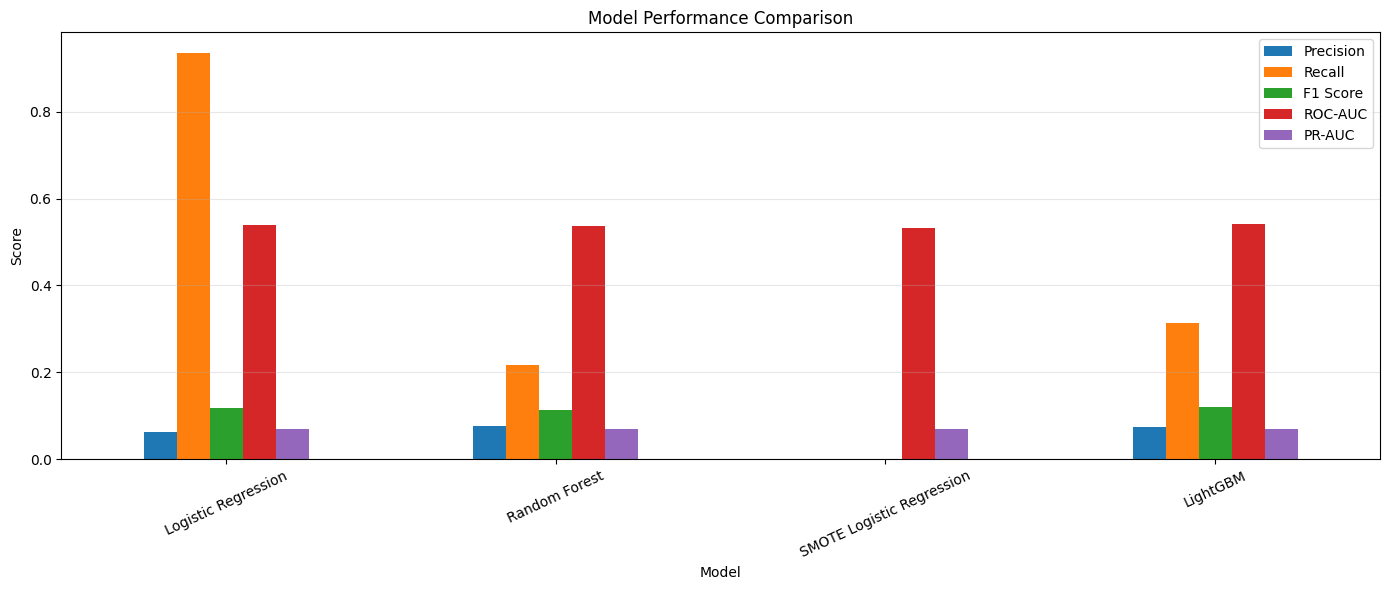

In [45]:

all_models = {
    'Logistic Regression': logistic_prob,
    'Random Forest': rf_prob,
    'SMOTE Logistic Regression': smote_prob,
    'LightGBM': lgbm_prob
}

comparison = []

for name, prob in all_models.items():

    pred = (prob >= 0.5).astype(int)

    comparison.append({
        'Model': name,
        'Precision': precision_score(
            y_val, pred, zero_division=0
        ),
        'Recall': recall_score(
            y_val, pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_val, pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_val, prob),
        'PR-AUC': average_precision_score(y_val, prob)
    })

comparison_df = pd.DataFrame(comparison)

display(
    comparison_df.sort_values(
        'ROC-AUC',
        ascending=False
    ).round(4)
)

# Visual comparison
comparison_df.set_index('Model')[
    ['Precision', 'Recall', 'F1 Score', 'ROC-AUC', 'PR-AUC']
].plot(
    kind='bar',
    figsize=(14, 6)
)

plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xticks(rotation=25)
plt.legend(loc='best')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [46]:

from sklearn.metrics import (
    precision_recall_curve,
    roc_curve
)

# Choose model with the highest validation PR-AUC
best_model_name = comparison_df.loc[
    comparison_df['PR-AUC'].idxmax(),
    'Model'
]

best_prob = all_models[best_model_name]

print("Best model by PR-AUC:", best_model_name)

# Calculate precision and recall across thresholds
precisions, recalls, thresholds = precision_recall_curve(
    y_val,
    best_prob
)

# Calculate F1 for each threshold
f1_values = (
    2 * precisions[:-1] * recalls[:-1] /
    (precisions[:-1] + recalls[:-1] + 1e-10)
)

best_index = np.argmax(f1_values)
best_threshold = thresholds[best_index]

print("Best threshold:", round(best_threshold, 4))
print("Best validation F1:", round(f1_values[best_index], 4))
print("Precision:", round(precisions[best_index], 4))
print("Recall:", round(recalls[best_index], 4))


Best model by PR-AUC: LightGBM
Best threshold: 0.4692
Best validation F1: 0.1252
Precision: 0.0722
Recall: 0.4694


In [47]:

threshold_results = []

for threshold in [0.3, 0.4, 0.5, best_threshold]:

    predictions = (
        best_prob >= threshold
    ).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_val, predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_val, predictions, zero_division=0
        ),
        'F1 Score': f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Precision,Recall,F1 Score
0,0.3000,0.0619,0.9777,0.1165
1,0.4000,0.0636,0.8637,0.1185
2,0.5000,0.0740,0.3142,0.1198
3,0.4692,0.0722,0.4694,0.1252


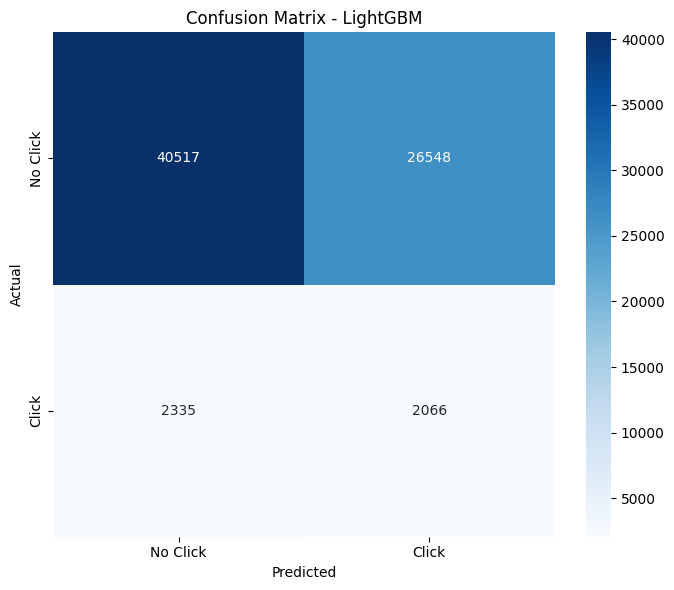

              precision    recall  f1-score   support

    No Click       0.95      0.60      0.74     67065
       Click       0.07      0.47      0.13      4401

    accuracy                           0.60     71466
   macro avg       0.51      0.54      0.43     71466
weighted avg       0.89      0.60      0.70     71466



In [48]:

from sklearn.metrics import ConfusionMatrixDisplay

best_predictions = (
    best_prob >= best_threshold
).astype(int)

cm = confusion_matrix(
    y_val,
    best_predictions
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Click', 'Click'],
    yticklabels=['No Click', 'Click']
)

plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

print(classification_report(
    y_val,
    best_predictions,
    target_names=['No Click', 'Click'],
    zero_division=0
))


<Figure size 800x600 with 0 Axes>

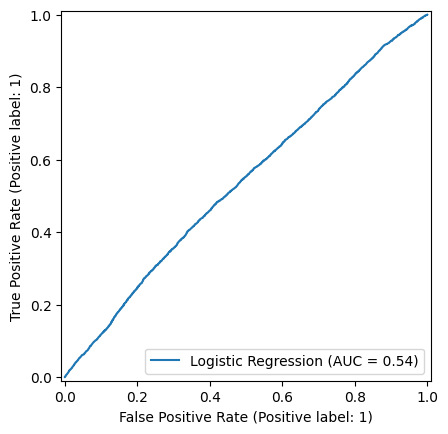

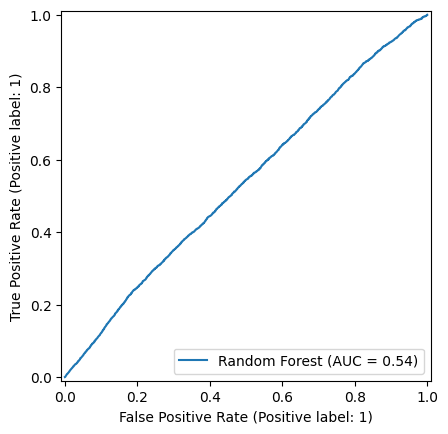

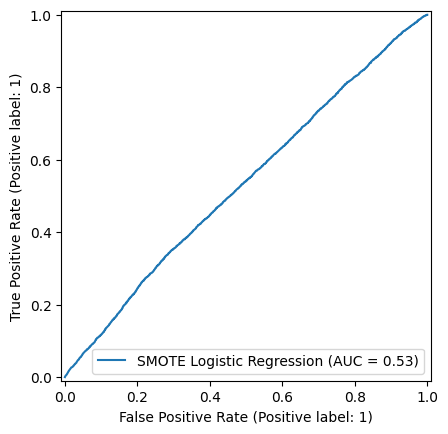

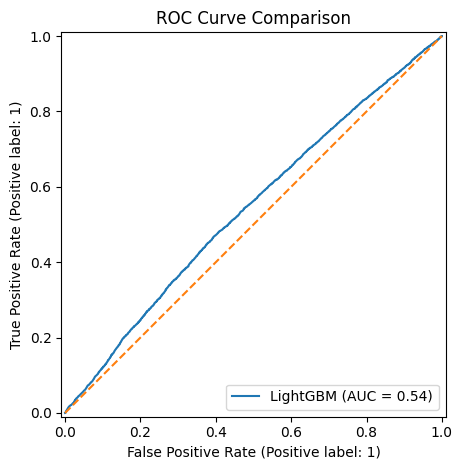

<Figure size 800x600 with 0 Axes>

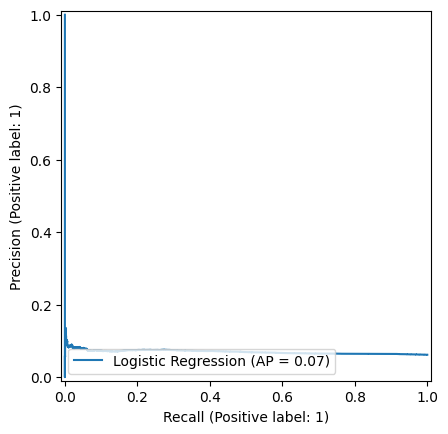

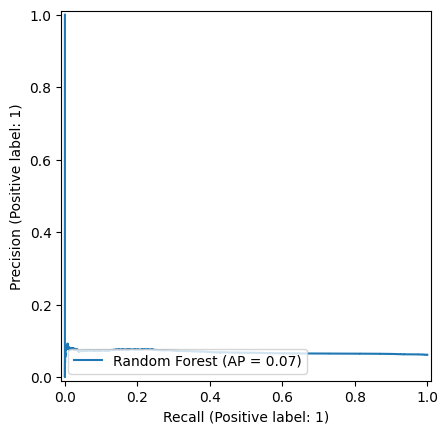

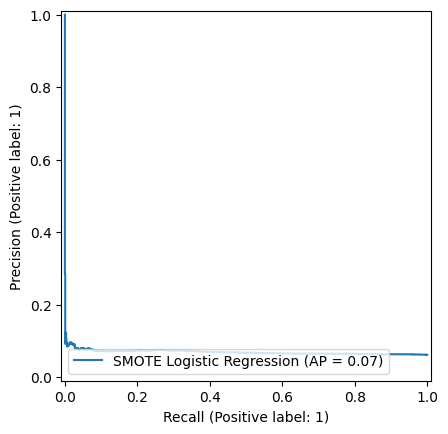

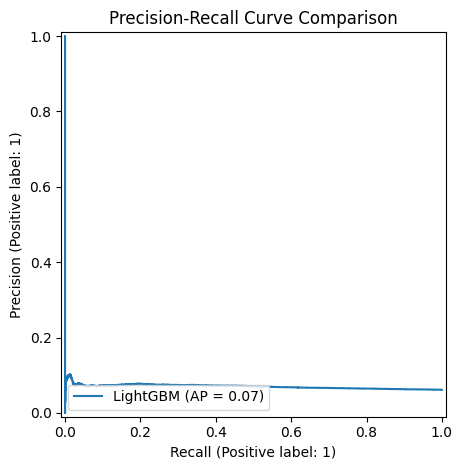

In [49]:

from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# ROC curve
plt.figure(figsize=(8, 6))

for name, probability in all_models.items():

    RocCurveDisplay.from_predictions(
        y_val,
        probability,
        name=name
    )

plt.plot([0, 1], [0, 1], '--')
plt.title('ROC Curve Comparison')
plt.tight_layout()
plt.show()

# Precision-recall curve
plt.figure(figsize=(8, 6))

for name, probability in all_models.items():

    PrecisionRecallDisplay.from_predictions(
        y_val,
        probability,
        name=name
    )

plt.title('Precision-Recall Curve Comparison')
plt.tight_layout()
plt.show()


TOP 20 IMPORTANT FEATURES


,Feature,Importance
0,num__user_historical_views,1743
12,num__hour,1736
3,num__product_historical_views,748
2,num__user_historical_ctr,742
5,num__product_historical_ctr,723
8,num__campaign_historical_ctr,617
6,num__campaign_historical_views,500
7,num__campaign_historical_clicks,369
95,cat__var_1_0,359
1,num__user_historical_clicks,309


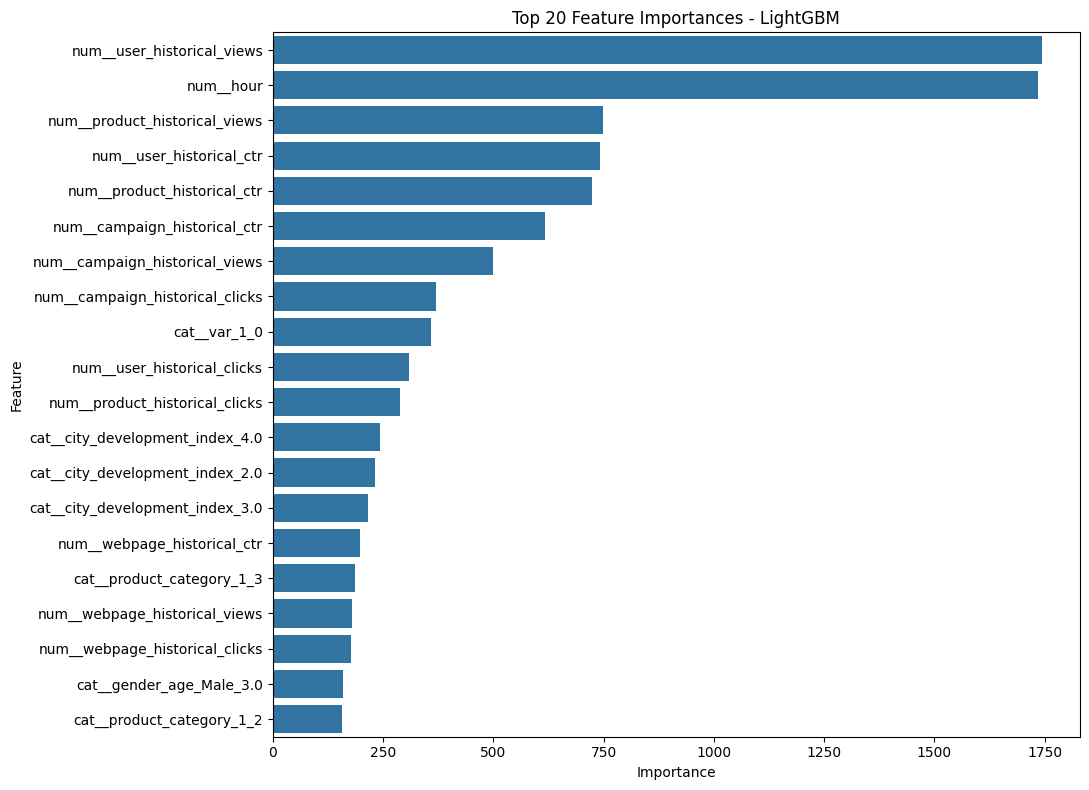

In [50]:

# Extract transformed feature names
feature_names = preprocessor.get_feature_names_out()

# LightGBM feature importance
importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': lgbm_model.feature_importances_
})

importance = importance.sort_values(
    'Importance',
    ascending=False
)

print("TOP 20 IMPORTANT FEATURES")
display(importance.head(20))

# Plot
plt.figure(figsize=(11, 8))

sns.barplot(
    data=importance.head(20),
    x='Importance',
    y='Feature'
)

plt.title('Top 20 Feature Importances - LightGBM')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


In [51]:

from lightgbm import LGBMClassifier
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import average_precision_score
from sklearn.base import clone

# Inner chronological split
inner_train = model_train_fe[
    model_train_fe['DateTime'].dt.day <= 5
].copy()

inner_val = model_train_fe[
    model_train_fe['DateTime'].dt.day == 6
].copy()

inner_drop = [
    'session_id', 'DateTime', 'user_id', 'is_click'
]

X_inner_train = inner_train.drop(columns=inner_drop)
y_inner_train = inner_train['is_click']

X_inner_val = inner_val.drop(columns=inner_drop)
y_inner_val = inner_val['is_click']

# Fit a fresh preprocessor on July 2-5 only
inner_preprocessor = clone(preprocessor)

X_inner_train_p = inner_preprocessor.fit_transform(
    X_inner_train
)

X_inner_val_p = inner_preprocessor.transform(
    X_inner_val
)

# Search space
param_grid = {
    'n_estimators': [300, 500, 700],
    'learning_rate': [0.02, 0.05, 0.08],
    'num_leaves': [15, 31, 50],
    'max_bin': [127, 255],
    'min_child_samples': [20, 50, 100],
    'reg_lambda': [0, 1, 5]
}

candidates = list(
    ParameterSampler(
        param_grid,
        n_iter=12,
        random_state=42
    )
)

tuning_results = []

inner_ratio = (
    (y_inner_train == 0).sum() /
    (y_inner_train == 1).sum()
)

for i, params in enumerate(candidates):

    model = LGBMClassifier(
        **params,
        scale_pos_weight=inner_ratio,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        X_inner_train_p,
        y_inner_train
    )

    probabilities = model.predict_proba(
        X_inner_val_p
    )[:, 1]

    score = average_precision_score(
        y_inner_val,
        probabilities
    )

    tuning_results.append({
        **params,
        'PR_AUC': score
    })

    print(
        f"Trial {i+1}/12 | PR-AUC: {score:.5f}"
    )

tuning_df = pd.DataFrame(tuning_results)

display(
    tuning_df.sort_values(
        'PR_AUC',
        ascending=False
    )
)

best_params = (
    tuning_df.sort_values(
        'PR_AUC',
        ascending=False
    ).iloc[0]
)

print("\nBest parameters:")
print(best_params)


Trial 1/12 | PR-AUC: 0.07791
Trial 2/12 | PR-AUC: 0.07884
Trial 3/12 | PR-AUC: 0.07708
Trial 4/12 | PR-AUC: 0.07756
Trial 5/12 | PR-AUC: 0.07739
Trial 6/12 | PR-AUC: 0.07799
Trial 7/12 | PR-AUC: 0.08059
Trial 8/12 | PR-AUC: 0.07874
Trial 9/12 | PR-AUC: 0.07803
Trial 10/12 | PR-AUC: 0.07795
Trial 11/12 | PR-AUC: 0.08145
Trial 12/12 | PR-AUC: 0.07655


,reg_lambda,num_leaves,n_estimators,min_child_samples,max_bin,learning_rate,PR_AUC
10,0,15,500,20,127,0.02,0.081447
6,1,31,300,50,127,0.05,0.080594
1,1,15,700,20,255,0.05,0.078844
7,0,15,500,100,127,0.05,0.078737
8,5,31,700,20,255,0.02,0.078029
5,0,50,300,100,255,0.08,0.077987
9,1,31,500,100,127,0.05,0.077947
0,0,50,500,20,255,0.08,0.077908
3,1,50,500,50,255,0.08,0.077562
4,1,31,500,50,127,0.08,0.077394



Best parameters:
reg_lambda             0.000000
num_leaves            15.000000
n_estimators         500.000000
min_child_samples     20.000000
max_bin              127.000000
learning_rate          0.020000
PR_AUC                 0.081447
Name: 10, dtype: float64


In [61]:
best_row = tuning_df.sort_values(
    'PR_AUC',
    ascending=False
).iloc[0]

best_params = {
    'n_estimators': int(best_row['n_estimators']),
    'learning_rate': float(best_row['learning_rate']),
    'num_leaves': int(best_row['num_leaves']),
    'max_bin': int(best_row['max_bin']),
    'min_child_samples': int(best_row['min_child_samples']),
    'reg_lambda': float(best_row['reg_lambda'])
}

print("Corrected best parameters:")
print(best_params)

Corrected best parameters:
{'n_estimators': 500, 'learning_rate': 0.02, 'num_leaves': 15, 'max_bin': 127, 'min_child_samples': 20, 'reg_lambda': 0.0}


In [52]:

weekend_analysis = train.copy()

weekend_analysis['day_type'] = np.where(
    weekend_analysis['DateTime'].dt.dayofweek >= 5,
    'Weekend',
    'Weekday'
)

weekend_results = (
    weekend_analysis.groupby('day_type')['is_click']
    .agg(['count', 'sum', 'mean'])
)

weekend_results['CTR (%)'] = (
    weekend_results['mean'] * 100
)

display(weekend_results)


,count,sum,mean,CTR (%)
day_type,,,,
Weekday,384246,25540,0.066468,6.646784
Weekend,79045,5791,0.073262,7.326207


In [53]:

product_business = calculate_ctr(
    train,
    'product'
)

display(
    product_business.sort_values(
        'ctr',
        ascending=False
    )
)


,product,impressions,clicks,ctr
9,J,9698,899,9.269953
3,D,41064,2949,7.181473
7,H,109574,7654,6.985234
2,C,163501,11306,6.914942
4,E,21452,1474,6.871154
8,I,63711,4079,6.402348
0,A,15391,953,6.191930
1,B,22479,1238,5.507362
5,F,7007,344,4.909376
6,G,9414,435,4.620778


In [54]:

# Features for the full model
personalized_columns = [
    col for col in X_train.columns
    if 'historical' in col
    or col in ['gender_age', 'campaign_webpage']
]

# Create baseline feature set
baseline_columns = [
    col for col in X_train.columns
    if col not in personalized_columns
]

baseline_preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, [
            c for c in numerical_columns
            if c not in personalized_columns
        ]),
        ('cat', categorical_transformer, [
            c for c in categorical_columns
            if c not in personalized_columns
        ])
    ]
)

X_base_train = baseline_preprocessor.fit_transform(
    X_train[baseline_columns]
)

X_base_val = baseline_preprocessor.transform(
    X_val[baseline_columns]
)

base_model = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    scale_pos_weight=imbalance_ratio,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

base_model.fit(X_base_train, y_train)

base_prob = base_model.predict_proba(
    X_base_val
)[:, 1]

# Compare predictive performance
personalization_comparison = pd.DataFrame({
    'Model': [
        'Without behavioral features',
        'With behavioral features'
    ],
    'ROC-AUC': [
        roc_auc_score(y_val, base_prob),
        roc_auc_score(y_val, lgbm_prob)
    ],
    'PR-AUC': [
        average_precision_score(y_val, base_prob),
        average_precision_score(y_val, lgbm_prob)
    ]
})

display(personalization_comparison)


,Model,ROC-AUC,PR-AUC
0,Without behavioral features,0.558458,0.074758
1,With behavioral features,0.542607,0.070149


In [55]:

smote_comparison = pd.DataFrame({
    'Model': [
        'Class-weighted Logistic Regression',
        'SMOTE Logistic Regression'
    ],
    'Precision': [
        precision_score(y_val, logistic_pred, zero_division=0),
        precision_score(y_val, smote_pred, zero_division=0)
    ],
    'Recall': [
        recall_score(y_val, logistic_pred, zero_division=0),
        recall_score(y_val, smote_pred, zero_division=0)
    ],
    'F1 Score': [
        f1_score(y_val, logistic_pred, zero_division=0),
        f1_score(y_val, smote_pred, zero_division=0)
    ],
    'PR-AUC': [
        average_precision_score(y_val, logistic_prob),
        average_precision_score(y_val, smote_prob)
    ]
})

display(smote_comparison)


,Model,Precision,Recall,F1 Score,PR-AUC
0,Class-weighted Logistic Regression,0.063244,0.935696,0.11848,0.069621
1,SMOTE Logistic Regression,0.000000,0.000000,0.00000,0.069147


In [56]:

inventory_analysis = calculate_ctr(
    train,
    'product'
)

inventory_analysis['Estimated_Clicks_Per_1000_Impressions'] = (
    inventory_analysis['ctr'] * 10
)

display(
    inventory_analysis.sort_values(
        'ctr',
        ascending=False
    )
)


,product,impressions,clicks,ctr,Estimated_Clicks_Per_1000_Impressions
9,J,9698,899,9.269953,92.699526
3,D,41064,2949,7.181473,71.814728
7,H,109574,7654,6.985234,69.852337
2,C,163501,11306,6.914942,69.149424
4,E,21452,1474,6.871154,68.711542
8,I,63711,4079,6.402348,64.023481
0,A,15391,953,6.191930,61.919303
1,B,22479,1238,5.507362,55.073624
5,F,7007,344,4.909376,49.093763
6,G,9414,435,4.620778,46.207776


In [57]:

profile_analysis = (
    train.groupby(
        ['gender', 'age_level', 'city_development_index'],
        dropna=False
    )['is_click']
    .agg(
        impressions='count',
        clicks='sum',
        ctr='mean'
    )
    .reset_index()
)

profile_analysis['CTR (%)'] = (
    profile_analysis['ctr'] * 100
)

# Avoid overinterpreting very small groups
profile_analysis = profile_analysis[
    profile_analysis['impressions'] >= 100
]

display(
    profile_analysis.sort_values(
        'CTR (%)',
        ascending=False
    ).head(20)
)


,gender,age_level,city_development_index,impressions,clicks,ctr,CTR (%)
34,Female,6.0,NaN,358,37,0.103352,10.335196
33,Female,6.0,4.0,152,15,0.098684,9.868421
67,Male,6.0,3.0,277,25,0.090253,9.025271
31,Female,6.0,2.0,255,23,0.090196,9.019608
63,Male,5.0,4.0,2945,255,0.086587,8.658744
69,Male,6.0,NaN,548,47,0.085766,8.576642
28,Female,5.0,4.0,1181,100,0.084674,8.467401
8,Female,1.0,4.0,123,10,0.081301,8.130081
29,Female,5.0,NaN,2717,220,0.080972,8.097166
44,Male,1.0,NaN,19921,1526,0.076603,7.660258


In [58]:

# Rebuild historical features using all labelled data
full_train_fe = build_historical_features(
    train,
    train
)

full_train_fe = add_model_features(full_train_fe)

# Test features use all available labelled training history
final_test_fe = build_historical_features(
    train,
    test
)

final_test_fe = add_model_features(final_test_fe)

# Prepare features and target
X_full = full_train_fe.drop(
    columns=[
        'session_id',
        'DateTime',
        'user_id',
        'is_click'
    ]
)

y_full = full_train_fe['is_click']

X_final_test = final_test_fe.drop(
    columns=[
        'session_id',
        'DateTime',
        'user_id'
    ]
)

X_final_test = X_final_test.reindex(
    columns=X_full.columns
)

print("Final training shape:", X_full.shape)
print("Final testing shape:", X_final_test.shape)


Final training shape: (463291, 31)
Final testing shape: (128858, 31)


In [59]:

final_preprocessor = clone(preprocessor)

X_full_processed = final_preprocessor.fit_transform(
    X_full
)

X_final_test_processed = final_preprocessor.transform(
    X_final_test
)

print("Final training processed:",
      X_full_processed.shape)

print("Final test processed:",
      X_final_test_processed.shape)


Final training processed: (463291, 126)
Final test processed: (128858, 126)


In [62]:

# Extract tuned parameters
best_params_dict = {
    key: best_params[key]
    for key in param_grid.keys()
}

# Recalculate imbalance ratio
final_ratio = (
    (y_full == 0).sum() /
    (y_full == 1).sum()
)

final_model = LGBMClassifier(
    **best_params_dict,
    scale_pos_weight=final_ratio,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

final_model.fit(
    X_full_processed,
    y_full
)

print("Final model successfully trained.")


Final model successfully trained.


In [63]:

# Predict probabilities
test_probabilities = final_model.predict_proba(
    X_final_test_processed
)[:, 1]

# Use validation-selected threshold
test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

# Prediction summary
print("Total test impressions:",
      len(test_predictions))

print("Predicted clicks:",
      test_predictions.sum())

print("Predicted non-clicks:",
      (test_predictions == 0).sum())

print("Predicted click percentage:",
      round(test_predictions.mean() * 100, 2), "%")


Total test impressions: 128858
Predicted clicks: 85500
Predicted non-clicks: 43358
Predicted click percentage: 66.35 %


In [64]:

submission = pd.DataFrame({
    'session_id': test['session_id'],
    'is_click': test_predictions
})

# Also retain probability predictions for business analysis
probability_output = pd.DataFrame({
    'session_id': test['session_id'],
    'click_probability': test_probabilities
})

submission.to_csv(
    'Ad_Click_Predictions.csv',
    index=False
)

probability_output.to_csv(
    'Ad_Click_Probabilities.csv',
    index=False
)

display(submission.head())

print("Submission file created.")
print("Prediction file shape:", submission.shape)


,session_id,is_click
0,411705,1
1,208263,1
2,239450,1
3,547761,0
4,574275,1


Submission file created.
Prediction file shape: (128858, 2)



# Business Recommendations and Strategic Conclusion

## 1. Intelligent Advertisement Targeting

Deploy the click prediction model to estimate the probability
of a user clicking on an advertisement. Use the probability
scores to prioritize relevant impressions.

## 2. Campaign Budget Optimization

Monitor campaign-level CTR and model predictions to identify
campaigns that deserve additional experimentation and budget.

## 3. Product-Level Advertising Optimization

Identify products with consistently strong click-through rates.
Investigate underperforming products and test alternative
advertising creatives and placements.

## 4. Personalized Advertising

Use historical engagement and contextual features to identify
audience segments that respond positively to particular products.

## 5. Class Imbalance Management

Use class weighting as a computationally efficient baseline.
Adopt SMOTE only if its validation performance justifies
its additional computational cost.

## 6. Continuous Model Monitoring

Monitor changes in click-through rates, prediction quality,
feature distributions and campaign behavior.

Retrain the model when meaningful performance deterioration
or data drift is detected.

## 7. Business Performance Measurement

Track:
- Click-through rate
- Precision and recall
- PR-AUC and ROC-AUC
- Cost per click
- Conversion rate
- Return on advertising spend

The current dataset supports click prediction and CTR analysis.
Financial ROI optimization requires additional cost and
conversion data.

## Final Conclusion

This project develops a machine learning framework for
predicting advertisement clicks using user, product,
campaign, webpage, temporal and historical behavioral
information.

The modeling process compares different classification
approaches and imbalance-handling techniques using
chronological validation.

The resulting framework can support more intelligent
advertising targeting, campaign experimentation and
resource allocation.

The final model should be deployed only after its predictive
performance, operational latency and business impact have
been validated.
